In [1]:
using Revise
using Plots
using LaTeXStrings

In [2]:
using LinearAlgebra: BLAS; BLAS.set_num_threads(1)

In [3]:
gr();
# pyplot();
# plotlyjs();

In [4]:
using GaussianSpectralDensities

In [5]:
include("example_problems.jl");

In [6]:
N_full = 1024
N = 128

σ = 0.5
τ = 0.8

λ = 0.0

ensemble_full = jordan(N_full, λ, σ, τ)
ensemble = jordan(N, λ, σ, τ)

# ensemble_full = circulant_from_jordan(N_full, λ, σ, τ)
# ensemble = circulant_from_jordan(N, λ, σ, τ)

# ensemble_full = annihilation(N_full, σ, τ)
# ensemble = annihilation(N, σ, τ)
# ensemble_full = toeplitz_from_annihilation(N_full, σ, τ)
# ensemble = toeplitz_from_annihilation(N, σ, τ)

# ensemble_full.T .= repeat(sqrt.([0.7; 0.5; 0.3]), N_full ÷ 3)
# ensemble.T .= repeat(sqrt.([0.7; 0.5; 0.3]), N ÷ 3)

ensemble.M

128×128 Tridiagonal{Float64,Array{Float64,1}}:
 0.0  1.0   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   …   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
 0.0  0.0  1.0   ⋅    ⋅    ⋅    ⋅    ⋅       ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅   0.0  0.0  1.0   ⋅    ⋅    ⋅    ⋅       ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅   0.0  0.0  1.0   ⋅    ⋅    ⋅       ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅   0.0  0.0  1.0   ⋅    ⋅       ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅   0.0  0.0  1.0   ⋅   …   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅   0.0  0.0  1.0      ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   0.0  0.0      ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   0.0      ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅       ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅   …   ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅       ⋅    ⋅    ⋅    ⋅    ⋅    ⋅    ⋅ 
  ⋅    ⋅    ⋅    

In [7]:
M_full_dense = Array(ensemble_full.M)
Mevs = unique(eigvals(M_full_dense))

Jr = (1 / sqrt(N_full)) * rand([-1.0; 1.0], (N_full, N_full))
Jr = SamplingUtils.partially_hermitize(Jr, τ)
Jrevs = eigvals(Jr)

Jc = (1 / sqrt(2N_full)) * (randn(N_full, N_full) + im * randn(N_full, N_full))
Jc = SamplingUtils.partially_hermitize(Jc, τ)
Jcevs = eigvals(Jc)

LJrR = ensemble_full.L * Jr * ensemble_full.R
Ar = M_full_dense + LJrR
Arevs = eigvals(Ar)

LJcR = ensemble_full.L * Jc * ensemble_full.R
Ac = M_full_dense + LJcR
Acevs = eigvals(Ac);

In [8]:
using LazySets: VPolygon, Bloating, overapproximate, radius

coords = reinterpret(real(eltype(Acevs)), reshape(Acevs, 1, :))
region = VPolygon(coords)
region = Bloating(region, 0.125 * radius(region))
region = overapproximate(region, 0.01 * radius(region))
bounds = overapproximate(region)

xcenter, ycenter = bounds.center
xradius, yradius = bounds.radius
xmin, xmax = xcenter - xradius, xcenter + xradius
ymin, ymax = ycenter - yradius, ycenter + yradius
xs = range(xmin, xmax; length=round(Int, 42 * xradius))
ys = range(ymin, ymax; length=round(Int, 42 * yradius));

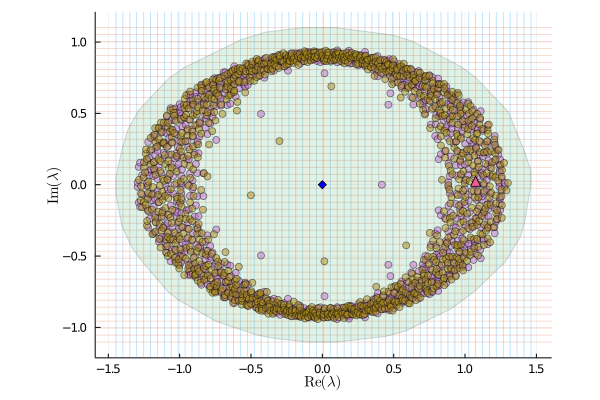

In [9]:
p = vline(xs, label="", alpha=0.25, xlims=(xs[1], xs[end]))
hline!(p, ys, label="", alpha=0.25, ylims=(ys[1], ys[end]))
plot!(
    p,
    region,
    alpha=0.15,
    aspect_ratio=:equal,
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)

scatter!(p, real(Arevs), imag(Arevs), alpha=0.5, label="")
scatter!(p, real(Acevs), imag(Acevs), alpha=0.5, label="")
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

i, j = 24, 53
scatter!(p, xs[[j]], ys[[i]], label="", markershape=:utriangle, markersize=5)

In [10]:
zs = [[x, y] in region ? complex(x, y) : missing for y in ys, x in xs]
za = zs[i, j + 1]
zb = zs[i - 1, j]
zc = zs[i, j]
objective = Fixk();

In [11]:
algorithm = Rampδ²()
solver = SpectralSolver(ensemble, objective, algorithm)
solutiona = solve!(solver, za; verbosity=3, store_trace=true);
solutionb = solve!(solver, zb; verbosity=3, store_trace=true);

 z =  1.123 + i 0.024
-------------------------------------------------------------------
    μ       γ²         δ²                  q                k
-------  ----------  ---------  ------------------------  ---------
  1.000   2.559e+02  2.560e+02   7.448e-03 + i-1.585e-04  3.777e-03
  1.000   1.279e+02  1.280e+02   1.419e-02 + i-3.037e-04  7.320e-03
  1.000   6.395e+01  6.400e+01   2.598e-02 + i-5.612e-04  1.383e-02
  1.000   3.196e+01  3.200e+01   4.465e-02 + i-9.793e-04  2.511e-02
  1.000   1.596e+01  1.600e+01   7.044e-02 + i-1.579e-03  4.327e-02
  1.000   7.974e+00  8.000e+00   1.009e-01 + i-2.320e-03  7.048e-02
  1.000   3.982e+00  4.000e+00   1.318e-01 + i-3.115e-03  1.093e-01
  1.000   1.988e+00  2.000e+00   1.598e-01 + i-3.873e-03  1.634e-01
  1.000   9.916e-01  1.000e+00   1.835e-01 + i-4.545e-03  2.387e-01
  1.000   4.942e-01  5.000e-01   2.029e-01 + i-5.120e-03  3.439e-01
  1.000   2.460e-01  2.500e-01   2.189e-01 + i-5.609e-03  4.919e-01
  1.000   1.222e-01  1.250e-01  

In [12]:
qa, δa² = solutiona.q, solutiona.δ²
qb, δb² = solutionb.q, solutionb.δ²
qc, δc² = GaussianSpectralDensities.select(qa, qb, δa², δb²)
GaussianSpectralDensities.print_q(qc)
GaussianSpectralDensities.print_δ²(δc²)
solutionc = solve!(
    solver, zc,
    qc, δc²;
    verbosity=3, store_trace=false,
);

 q =  2.219e-01 + i-3.757e-04
δ² =  6.309e-02
 z =  1.074 + i 0.024
-------------------------------------------------------------------
    μ       γ²         δ²                  q                k
-------  ----------  ---------  ------------------------  ---------
  1.000   6.380e-02  6.388e-02   2.001e-01 + i-5.309e-03  1.000e+00
-------------------------------------------------------------------


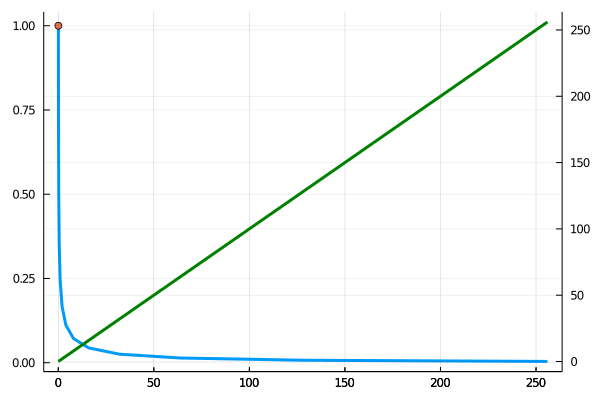

In [13]:
sol = solutionb
plot(sol.trace.γ², sol.trace.k, lw=3, label="")
scatter!([sol.γ²], [sol.k], label="")
plot!(twinx(), sol.trace.γ², sol.trace.δ², lw=3, color=:green, label="")

In [14]:
problem = SpectralProblem(zs, objective, ensemble)
solution = solve(problem, algorithm; chunks_per_thread=1);

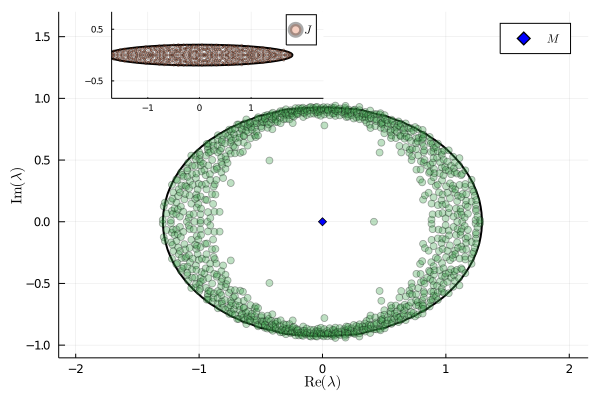

In [15]:
p = contour(
    xs,
    ys,
    solution.γ²,
    levels=[0.0],
    #solution.k,
    #levels=[1.0],
    linewidth=2,
    color=:black,
    colorbar_entry=false,
    aspect_ratio=:equal,
    #size=(270, 200),
    ylims=(ys[1], ys[end] + 0.6),
    xlabel=L"\mathrm{Re}(\lambda)",
    ylabel=L"\mathrm{Im}(\lambda)",
    tickfontsize=8,
    guidefontsize=10,
)
scatter!(
    p,
    real(Mevs),
    imag(Mevs),
    markershape=:diamond,
    markercolor=:blue,
    aspect_ratio=:equal,
    label=L"M",
)

plot!(
    p,
    t -> (1 + τ) * cos(t),
    t -> (1 - τ) * sin(t),
    0,
    2pi,
    linewidth=2,
    color=:black,
    aspect_ratio=:equal,
    label="",
    xlims=(-1.7, 2.4),
    xticks=[-1.0; 0.0; 1.0],
    yticks=[-0.5; 0.5],
    tickfontsize=6,
    inset_subplots=(1, bbox(0.1, 0.0, 0.4, 0.25)),
    subplot=2,
)

scatter!(
    p,
    real(Arevs),
    imag(Arevs),
    #real(Acevs),
    #imag(Acevs),
    #markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    #label=L"M + 0.95 J",
    label="",
    subplot=1,
)

scatter!(
    p,
    real(Jrevs),
    imag(Jrevs),
    #real(Jcevs),
    #imag(Jcevs),
    markersize=1.15,
    alpha=1.0 / 3.0,
    aspect_ratio=:equal,
    label=L"J",
    subplot=2,
)

p

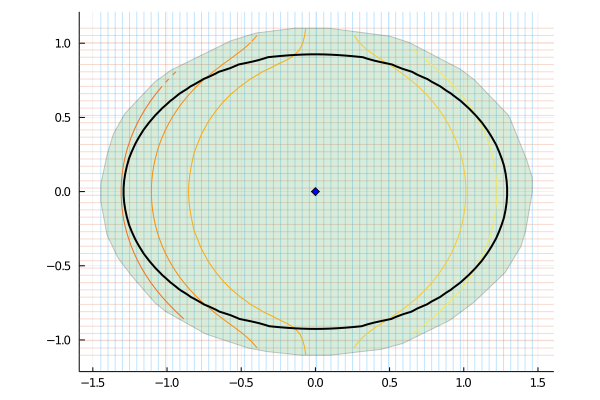

In [16]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, real(solution.q), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, lw=2)
# contour!(p, xs, ys, solution.k, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

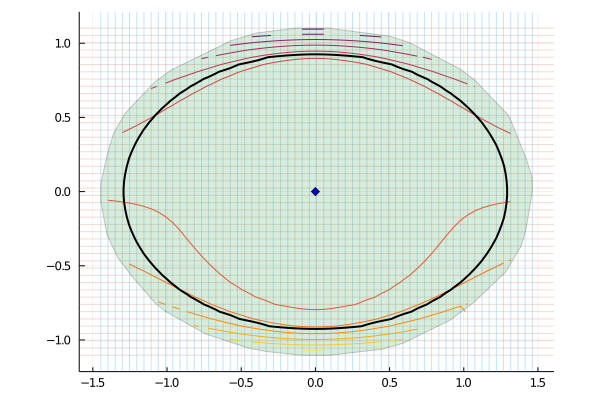

In [17]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, imag(solution.q), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, lw=2)
# contour!(p, xs, ys, solution.k, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

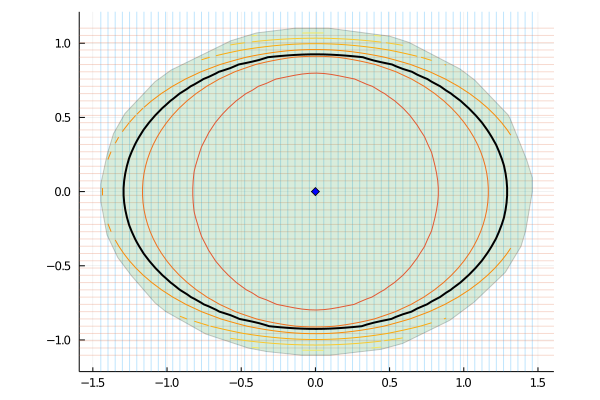

In [18]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, abs.(solution.q), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, lw=2)
# contour!(p, xs, ys, solution.k, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

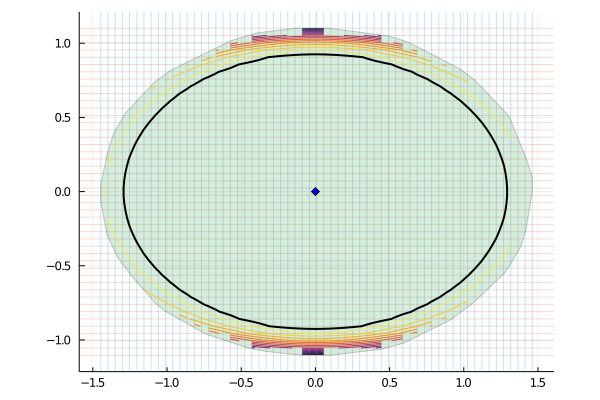

In [19]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, solution.γ², aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, lw=2)
# contour!(p, xs, ys, solution.k, aspect_ratio=:equal, colorbar=false)
# contour!(p, xs, ys, solution.k, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

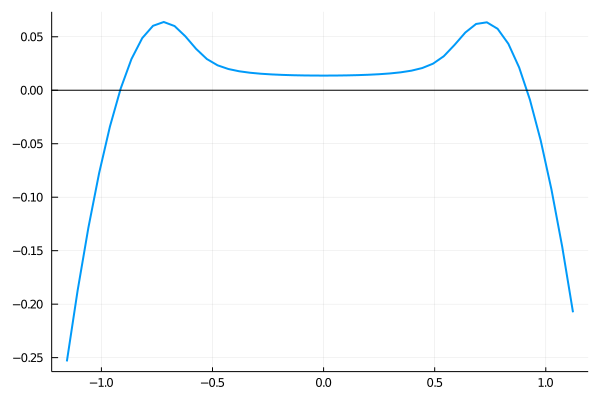

In [20]:
p = plot(real(zs[37, :]), solution.γ²[37,:], lw=2, label="")
# p = plot(real(zs[37, :]), solution.k[37,:], lw=2, label="")
hline!(p, [0.0], color=:black, label="")

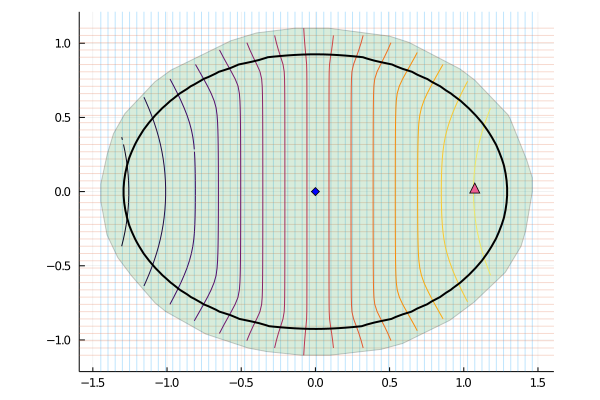

In [21]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, real((zs / σ) - sqrt(τ) * solution.q), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, lw=2)
# contour!(p, xs, ys, solution.k, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

i, j = 24, 53
scatter!(p, xs[[j]], ys[[i]], label="", markershape=:utriangle, markersize=5)

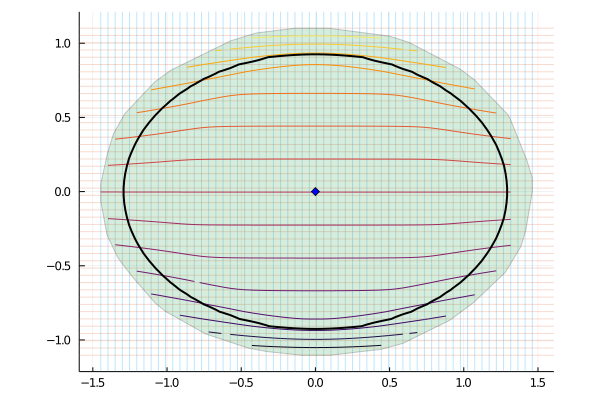

In [22]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, imag((zs / σ) - sqrt(τ) * solution.q), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, lw=2)
# contour!(p, xs, ys, solution.k, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

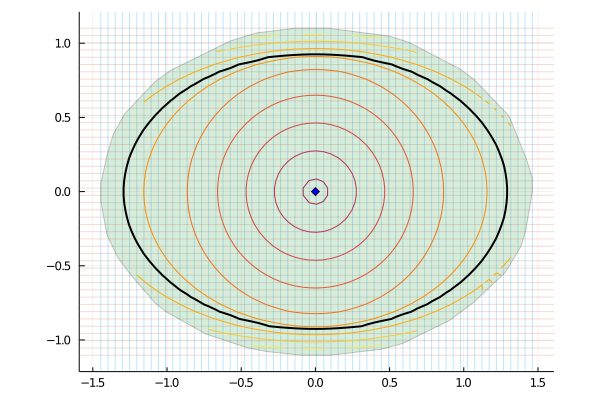

In [23]:
p = vline(xs, label="", xlims=(xs[1], xs[end]), alpha=0.25)
hline!(p, ys, label="", ylims=(ys[1], ys[end]), alpha=0.25)
plot!(p, region, alpha=0.2)
contour!(p, xs, ys, abs.((zs / σ) - sqrt(τ) * solution.q), aspect_ratio=:equal, colorbar=false)
contour!(p, xs, ys, solution.γ², levels=[0.0], color=:black, lw=2)
# contour!(p, xs, ys, solution.k, levels=[1.0], color=:black, lw=2)
scatter!(p, real(Mevs), imag(Mevs), markershape=:diamond, markercolor=:blue, label="")

In [24]:
# Jacobian check
using GaussianSpectralDensities: workspace, qf!, qj!
using GaussianSpectralDensities: @SVector, finite_difference_jacobian

ws = workspace(ensemble)
z = -1.13 + 0.02im
obj = Fixγ²{false}(0.2)
q = -0.23 + 0.58im
qv = @SVector [real(q), imag(q)];

In [25]:
# Analytical
qj!(ws, obj, z, qv)

2×2 StaticArrays.SArray{Tuple{2,2},Float64,2,4} with indices SOneTo(2)×SOneTo(2):
 -1.27572    -0.0400572
  0.0400572  -0.886822

In [26]:
# Numerical
finite_difference_jacobian(qv -> qf!(ws, obj, z, qv), qv)

2×2 StaticArrays.SArray{Tuple{2,2},Float64,2,4} with indices SOneTo(2)×SOneTo(2):
 -1.27572    -0.0400572
  0.0400572  -0.886822